# Object Detection: what does "it found 80 kinds of object" really mean?

**The question:** the legacy script runs **SSD MobileNet v3**, a small neural network trained on the COCO dataset, on webcam frames through OpenCV: it draws a green box and a name for every object it is at least 50% sure about. It is fast and the demo looks impressive when a person and a cup are on the desk. *But how good is it, in numbers? How does its accuracy depend on the size of the object, on how crowded the scene is and on the confidence threshold? How does it compare with an equivalent network and with a much bigger one, and what does the extra accuracy cost in time?* We test on **500 random COCO validation images with 3,671 hand-labelled objects**, using the official COCO evaluation (mAP).

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the images and the objects
4. Hypotheses and why we chose each test
5. The three detectors
6. H1: how accurate is the legacy detector, and how does it compare?
7. H2: does the size of the object decide?
8. H3: where should the confidence threshold sit?
9. H4: crowded scenes and difficult categories
10. H5: what does accuracy cost in time?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab CV/object-detection/object_detection.ipynb`, or *Run All* in any Jupyter. The COCO annotations (about 250 MB), the 500 images (about 80 MB) and the three models (about 230 MB) download themselves on the first run. It uses a GPU if present and takes about 10 minutes on one.

## 1. 💡 The simple analogy

Imagine a **lifeguard scanning a crowded beach for swimmers in trouble**, reporting each one with how sure they are.

- A **big, close swimmer** is easy to spot; a **tiny swimmer far away** is easy to miss.
- On a **quiet beach** the lifeguard names everyone; in a **packed one** people overlap and some go unreported.
- Saying "I am only reporting what I am 50% sure of" is a **choice**: report more and you raise false alarms, report less and you miss people.
- A **second lifeguard with binoculars and more training** sees more, but takes longer to scan the beach.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of images (500), the legacy confidence threshold (0.5) and the overlap needed to count a detection as correct keeps the notebook reproducible and avoids "magic numbers". Detections are kept down to a score of 0.01, so the full precision-recall curve (which mAP needs) exists, and the legacy threshold of 0.5 is applied later.

In [1]:
import contextlib
import io
import tarfile
import time
import urllib.request
import zipfile
from functools import partial
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from scipy import stats
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    SSDLite320_MobileNet_V3_Large_Weights,
    fasterrcnn_resnet50_fpn_v2,
    ssdlite320_mobilenet_v3_large,
)

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
N_IMAGES = 500
N_FOLDS = 10  # delete-one-fold jackknife for the uncertainty of every mAP
LEGACY_THRESHOLD = 0.5  # the confidence threshold the legacy script used
IOU_MATCH = 0.5
LOW_SCORE = 0.01  # detections are kept down to this score so the full precision-recall curve exists
USER_AGENT = {"User-Agent": "Mozilla/5.0"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
(DATA_DIR / "images").mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the images and the objects

*What:* the COCO **val2017** set: 5,000 photographs with hand-drawn boxes and names for 80 kinds of everyday object. We draw 500 at random, download them and count what is in them: objects per image, object sizes (by COCO's convention: small below 32 x 32 pixels, large above 96 x 96) and the most common categories. *Why:* a detector's score depends on what it is shown: crowded scenes and small objects are harder.

> **Problems in the legacy script this replaces:** it needs a live webcam and shows detections only on frames that contain one (`imshow` sits inside the `if`, so the picture freezes when nothing is detected); it prints the text at `(box[0] + 10, box[0] + 30)`, using the box's *x* coordinate for the vertical position; its model weights (the `.pb` file) were not in the repository; and it never measures a score.

In [2]:
def download(url: str, target: Path) -> None:
    """Downloads a file once (a browser-like header is needed by some hosts)."""
    if not target.exists():
        request = urllib.request.Request(url, headers=USER_AGENT)
        with urllib.request.urlopen(request, timeout=120) as response:
            target.write_bytes(response.read())


annotations = DATA_DIR / "annotations" / "instances_val2017.json"
if not annotations.exists():
    archive = DATA_DIR / "annotations_trainval2017.zip"
    download("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", archive)
    with zipfile.ZipFile(archive) as zf:
        zf.extract("annotations/instances_val2017.json", DATA_DIR)
legacy_weights = DATA_DIR / "ssd_mobilenet_v3_large_coco_2020_01_14.pb"
if not legacy_weights.exists():
    tarball = DATA_DIR / "ssd_mobilenet_v3_large_coco_2020_01_14.tar.gz"
    download(
        "http://download.tensorflow.org/models/object_detection/"
        "ssd_mobilenet_v3_large_coco_2020_01_14.tar.gz",
        tarball,
    )
    with tarfile.open(tarball) as tf:
        member = "ssd_mobilenet_v3_large_coco_2020_01_14/frozen_inference_graph.pb"
        legacy_weights.write_bytes(tf.extractfile(member).read())

with contextlib.redirect_stdout(io.StringIO()):
    coco = COCO(str(annotations))
all_ids = sorted(coco.getImgIds())
image_ids = sorted(int(i) for i in rng.choice(all_ids, N_IMAGES, replace=False))
for image_id in image_ids:
    download(
        f"http://images.cocodataset.org/val2017/{image_id:012d}.jpg",
        DATA_DIR / "images" / f"{image_id:012d}.jpg",
    )

anns = coco.loadAnns(coco.getAnnIds(imgIds=image_ids, iscrowd=False))
sizes = pd.Series([a["area"] for a in anns])
counts = pd.Series([len(coco.getAnnIds(imgIds=[i], iscrowd=False)) for i in image_ids])
names = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
print(
    f"COCO val2017 has {len(all_ids):,} images; {N_IMAGES} drawn at random "
    f"({len(anns):,} labelled objects in {len(names)} categories)"
)
print(
    f"Objects per image: median {counts.median():.0f}, mean {counts.mean():.1f}, 90th "
    f"percentile {counts.quantile(0.9):.0f}, most {counts.max()}; images with no object: "
    f"{int((counts == 0).sum())}"
)
small, medium = (sizes < 32**2).mean(), ((sizes >= 32**2) & (sizes < 96**2)).mean()
print(
    f"Object size (COCO convention, pixel area): small {small:.0%}, medium {medium:.0%}, "
    f"large {1 - small - medium:.0%}"
)
top = pd.Series([names[a["category_id"]] for a in anns]).value_counts()
print("Most common: " + ", ".join(f"{k} {v / len(anns):.0%}" for k, v in top.head(5).items()))
print(
    f"Categories with fewer than 5 objects in this sample: {int((top < 5).sum())} of {len(names)}"
)

COCO val2017 has 5,000 images; 500 drawn at random (3,671 labelled objects in 80 categories)
Objects per image: median 4, mean 7.3, 90th percentile 18, most 38; images with no object: 4
Object size (COCO convention, pixel area): small 41%, medium 36%, large 24%
Most common: person 32%, car 6%, chair 5%, book 3%, bottle 3%
Categories with fewer than 5 objects in this sample: 4 of 80


**How to read this:**

- **500 images with 3,671 labelled objects** in 80 categories; the median image has **4** objects, the mean 7.3, the 90th percentile 18 and the busiest has **38**. Four images have no object at all.
- **Many of the objects are small:** **41%** are small, **36%** medium and **24%** large.
- **Persons dominate:** 32% of the objects are people, then cars (6%), chairs (5%), books (3%) and bottles (3%). Four categories have fewer than 5 objects in this sample, so their scores are noisy.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does a bigger, newer detector beat the legacy one, and does the equivalent MobileNet network match it? | Same mAP | Differs | COCO mAP with a delete-one-fold jackknife for the uncertainty; jackknife z-score of the difference |
| H2 | Do all three detectors find small objects as well as large ones? | Same AP for every size | Small objects are much harder | AP for small, medium and large objects with 95% jackknife intervals |
| H3 | Is the legacy 0.5 confidence threshold a good operating point? | It gives the best balance | Another threshold is better | Precision, recall and F1 on one half of the images (to choose) and the other half (to judge) |
| H4 | Do crowded scenes and some categories hurt the legacy detector? | Same recall everywhere | Falls with the number of objects | Spearman correlation and Kruskal-Wallis; AP by category |
| H5 | Is the more accurate detector slower? | Same time | Slower | Median time per image with a bootstrap interval |

*Why these tests?* **mAP** (mean average precision) is the standard score: for each category it averages precision over all recall levels and over overlap thresholds from 0.5 to 0.95, then averages over categories. Because it needs the whole detection list, it has no simple standard error, so we use a **delete-one-fold jackknife**: we leave out each tenth of the images in turn, recompute the score, and use the spread. Precision, recall and F1 at a threshold are easy to read and show what the legacy 0.5 does.

## 5. The three detectors

*What:* all three are trained on COCO and see each image once at their own input size.

1. **Legacy: SSD MobileNet v3 Large (TensorFlow, 2020), through OpenCV's `dnn` module** (320 x 320 input), exactly the model and settings of the legacy script. The TensorFlow graph always returns its 100 best boxes, so there are 100 detections per image.
2. **SSDlite MobileNet v3 Large (torchvision):** the same family of network, trained and released by a different team; it shows how much of the legacy result belongs to the *design* of the network.
3. **Faster R-CNN ResNet-50 FPN v2 (torchvision):** a much larger two-stage detector, the "accurate but slower" end.

A detection is **correct** if it has the right category and overlaps the true box by at least 50% (IoU 0.5; mAP also averages thresholds up to 0.95).

In [3]:
legacy_net = cv2.dnn_DetectionModel(
    str(legacy_weights), "SSD_MobileNet_v3/ssd_mobilenet_v3_large_coco_2020_01_14.pbtxt"
)
legacy_net.setInputSize(320, 320)
legacy_net.setInputScale(1.0 / 127.5)
legacy_net.setInputMean((127.5, 127.5, 127.5))
legacy_net.setInputSwapRB(True)


def detect_legacy(image: np.ndarray) -> list[dict]:
    """The legacy model (SSD MobileNet v3 through OpenCV), keeping low-score detections.

    Args:
        image: BGR image.

    Returns:
        COCO-style detections: ``category_id``, ``bbox`` (x, y, width, height) and ``score``.
    """
    ids, scores, boxes = legacy_net.detect(image, confThreshold=LOW_SCORE)
    if len(ids) == 0:
        return []
    return [
        {"category_id": int(i), "bbox": [float(v) for v in b], "score": float(s)}
        for i, s, b in zip(ids.flatten(), scores.flatten(), boxes, strict=True)
    ]


def detect_torch(model: torch.nn.Module, image: np.ndarray) -> list[dict]:
    """Runs a torchvision detector on a BGR image; returns COCO-style detections."""
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(DEVICE)
    with torch.no_grad():
        out = model([tensor])[0]
    boxes = out["boxes"].cpu().numpy()
    return [
        {
            "category_id": int(label),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
            "score": float(score),
        }
        for b, label, score in zip(
            boxes, out["labels"].cpu().numpy(), out["scores"].cpu().numpy(), strict=True
        )
    ]


ssdlite = (
    ssdlite320_mobilenet_v3_large(
        weights=SSDLite320_MobileNet_V3_Large_Weights.COCO_V1,
        score_thresh=LOW_SCORE,
        detections_per_img=100,
        progress=False,
    )
    .to(DEVICE)
    .eval()
)
faster_rcnn = (
    fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
        box_score_thresh=LOW_SCORE,
        box_detections_per_img=100,
        progress=False,
    )
    .to(DEVICE)
    .eval()
)
models = {
    "Legacy: SSD MobileNet v3 (OpenCV)": detect_legacy,
    "SSDlite MobileNet v3 (torchvision)": partial(detect_torch, ssdlite),
    "Faster R-CNN ResNet-50 v2 (torchvision)": partial(detect_torch, faster_rcnn),
}
images = {i: cv2.imread(str(DATA_DIR / "images" / f"{i:012d}.jpg")) for i in image_ids}
detections = {}
for name, fn in models.items():
    start = time.perf_counter()
    detections[name] = {i: fn(images[i]) for i in image_ids}
    seconds = time.perf_counter() - start
    n_det = sum(len(v) for v in detections[name].values())
    print(
        f"{name}: {n_det:,} detections with score of at least {LOW_SCORE} "
        f"({n_det / N_IMAGES:.0f} per image), {seconds / N_IMAGES * 1000:.0f} ms per image "
        f"on {'CPU (OpenCV)' if 'OpenCV' in name else DEVICE}"
    )

Legacy: SSD MobileNet v3 (OpenCV): 50,000 detections with score of at least 0.01 (100 per image), 31 ms per image on CPU (OpenCV)


SSDlite MobileNet v3 (torchvision): 48,242 detections with score of at least 0.01 (96 per image), 55 ms per image on cuda


Faster R-CNN ResNet-50 v2 (torchvision): 29,936 detections with score of at least 0.01 (60 per image), 94 ms per image on cuda


**How to read this:** the three detectors produce **50,000** (100 per image, the cap of the legacy graph), **48,242** (96 per image) and **29,936** (60 per image) detections with a score of at least 0.01 on the 500 images.

## 6. H1: how accurate is the legacy detector, and how does it compare?

*What:* the official COCO evaluation (`pycocotools`) of each detector on the same 500 images: mAP over IoU 0.5 to 0.95, AP at IoU 0.5 and 0.75, and AP for small, medium and large objects. The uncertainty comes from a **delete-one-fold jackknife** (ten folds of 50 images), and we compare each detector with the legacy one using the jackknife standard error of the difference. *Why:* a number without an error bar cannot say whether a difference is real.

In [4]:
def evaluate(dets: dict[int, list[dict]], ids: list[int]) -> np.ndarray:
    """COCO evaluation (the 12 standard numbers) of detections on a set of images.

    Args:
        dets: Detections per image id.
        ids: The images to score.

    Returns:
        The COCOeval statistics: AP, AP50, AP75, AP small/medium/large, AR 1/10/100, AR s/m/l.
    """
    results = [dict(d, image_id=i) for i in ids for d in dets[i]]
    if not results:
        return np.zeros(12)
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(coco, coco.loadRes(results), "bbox")
        ev.params.imgIds = ids
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    return np.array(ev.stats)


STAT_NAMES = ["mAP", "AP50", "AP75", "AP small", "AP medium", "AP large"]
STAT_INDEX = [0, 1, 2, 3, 4, 5]
folds = np.array_split(rng.permutation(image_ids), N_FOLDS)
rows = []
fold_stats = {}
for name, dets in detections.items():
    full = evaluate(dets, image_ids)
    leave_out = np.array(
        [evaluate(dets, [i for i in image_ids if i not in set(f.tolist())]) for f in folds]
    )
    fold_stats[name] = leave_out
    se = np.sqrt((N_FOLDS - 1) / N_FOLDS * ((leave_out - leave_out.mean(0)) ** 2).sum(0))
    for k, label in zip(STAT_INDEX, STAT_NAMES, strict=True):
        rows.append({"model": name, "metric": label, "value": full[k] * 100, "se": se[k] * 100})
scores = pd.DataFrame(rows)
table = scores.pivot(index="model", columns="metric", values="value")[STAT_NAMES]
print(table.round(1).to_string())
print("\n(jackknife standard errors, in points)")
print(scores.pivot(index="model", columns="metric", values="se")[STAT_NAMES].round(1).to_string())
base = list(detections)[0]
for name in list(detections)[1:]:
    diff = fold_stats[name][:, 0] - fold_stats[base][:, 0]
    se = np.sqrt((N_FOLDS - 1) / N_FOLDS * ((diff - diff.mean()) ** 2).sum()) * 100
    full_diff = table.loc[name, "mAP"] - table.loc[base, "mAP"]
    print(
        f"{name} minus legacy, mAP: {full_diff:+.1f} points (jackknife SE {se:.1f}, "
        f"z = {full_diff / se:.1f})"
    )

metric                                    mAP  AP50  AP75  AP small  AP medium  AP large
model                                                                                   
Faster R-CNN ResNet-50 v2 (torchvision)  48.1  68.4  52.2      33.6       51.7      64.7
Legacy: SSD MobileNet v3 (OpenCV)        27.6  45.4  28.4       5.3       28.5      59.4
SSDlite MobileNet v3 (torchvision)       22.1  35.6  22.8       1.2       22.1      51.0

(jackknife standard errors, in points)
metric                                   mAP  AP50  AP75  AP small  AP medium  AP large
model                                                                                  
Faster R-CNN ResNet-50 v2 (torchvision)  2.0   2.2   2.8       2.4        2.1       2.9
Legacy: SSD MobileNet v3 (OpenCV)        0.9   1.2   1.2       1.2        2.1       2.1
SSDlite MobileNet v3 (torchvision)       1.3   1.7   2.1       0.5        1.9       3.1
SSDlite MobileNet v3 (torchvision) minus legacy, mAP: -5.5 points (jackknif

**How to read this:**

| Detector | mAP | AP at IoU 0.5 | AP at IoU 0.75 |
|---|---|---|---|
| Faster R-CNN ResNet-50 v2 | **48.1** (SE 2.0) | 68.4 | 52.2 |
| **Legacy: SSD MobileNet v3 (OpenCV)** | **27.6** (SE 0.9) | 45.4 | 28.4 |
| SSDlite MobileNet v3 (torchvision) | 22.1 (SE 1.3) | 35.6 | 22.8 |

- **The legacy detector reaches 27.6 mAP** on these 500 images: about half of the objects it should find are found with a well-placed box, and a typical box is placed well enough (AP 45.4 at IoU 0.5) but loosely (AP 28.4 at IoU 0.75).
- **The big detector is far better:** Faster R-CNN is **+20.5 points** above the legacy (jackknife SE 1.6, z = 13), almost twice the mAP. **We reject H₀.**
- **The "same" network from another team is worse:** SSDlite is **5.5 points below** the legacy (SE 0.7, z = -7.5). The legacy TensorFlow model was trained with a better recipe than torchvision's: the architecture is not the whole story.
- **A caution:** the legacy mAP here is higher than the roughly 22 listed in the TensorFlow model zoo for this model, and a second random sample of 500 images (checked outside this notebook) gave 29.0, so the gap is not just sampling noise. We did not find the cause (a different evaluation image set, or a different post-processing, are possible).

## 7. H2: does the size of the object decide?

*What:* COCO splits objects by pixel area: small (under 32 x 32), medium (32 x 32 to 96 x 96) and large (over 96 x 96). We report AP for each size for the three detectors, with 95% jackknife intervals. *Why:* a webcam demo shows large objects; a camera across a room sees small ones.

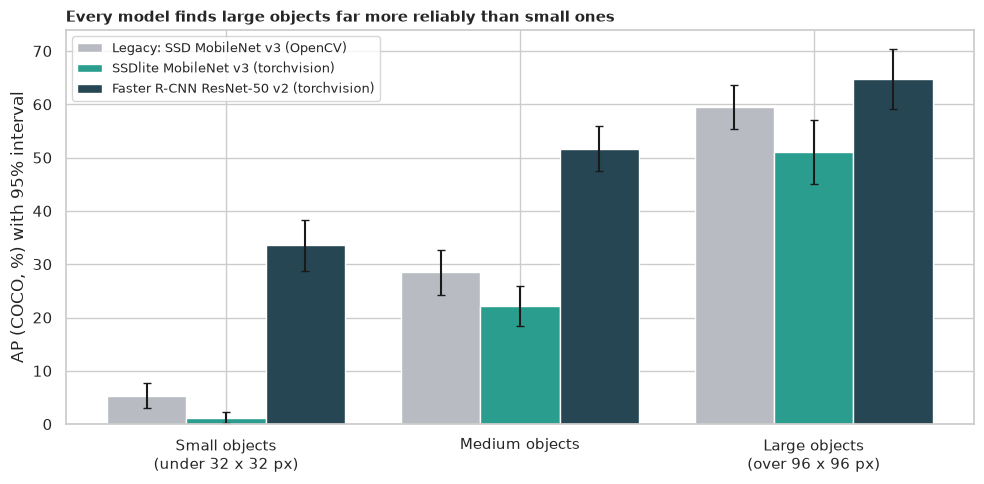

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
colors = [GREY, TEAL, NAVY]
for k, (name, color) in enumerate(zip(detections, colors, strict=True)):
    sub = (
        scores[scores["model"] == name]
        .set_index("metric")
        .loc[["AP small", "AP medium", "AP large"]]
    )
    ax.bar(
        x + (k - 1) * 0.27,
        sub["value"],
        0.27,
        color=color,
        label=name,
        yerr=1.96 * sub["se"],
        capsize=3,
    )
ax.set_xticks(
    x, ["Small objects\n(under 32 x 32 px)", "Medium objects", "Large objects\n(over 96 x 96 px)"]
)
ax.set_ylabel("AP (COCO, %) with 95% interval")
ax.set_title(
    "Every model finds large objects far more reliably than small ones",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_ap_by_size.png", dpi=150)
plt.show()

**How to read this:**

- **Small objects are where the small detectors fail:** the legacy detector gets **5.3** AP on small objects (SE 1.2) against **28.5** on medium and **59.4** on large objects: a factor of **11** between small and large. SSDlite is nearly blind to small objects (**1.2**) and the big detector gets **33.6**.
- **Every detector is best on large objects:** Faster R-CNN **64.7**, legacy **59.4**, SSDlite **51.0**. On large objects the legacy detector is within 5 points of the big one.
- **The advantage of the big detector is concentrated in small and medium objects:** +28.3 points on small, +23.2 on medium and +5.3 on large, against the legacy. **We reject H₀.**
- **The webcam demo flatters it:** an object held up to the camera is large; the legacy detector is at its best exactly there, and 41% of the objects in everyday photographs are small.

## 8. H3: where should the confidence threshold sit?

*What:* the legacy script reports every detection with a score of at least **0.5**. We count, for thresholds from 0.10 to 0.95, the detections that are right (true positives), wrong (false positives) and the objects missed (false negatives), using greedy matching at IoU 0.5 within each category, and compute precision, recall and F1. The best threshold is chosen on the first half of the images and judged on the second. *Why:* the threshold is the user's real control, and 0.5 is a habit.

In [6]:
def match_counts(
    dets: dict[int, list[dict]], ids: list[int], threshold: float
) -> tuple[int, int, int]:
    """True positives, false positives and missed objects at a confidence threshold.

    Detections are taken from the most to the least confident; each claims the best unclaimed
    object of the same category with an IoU of at least ``IOU_MATCH``. Crowd regions are ignored.

    Args:
        dets: Detections per image id.
        ids: Images to count over.
        threshold: Minimum score of a detection to count.

    Returns:
        The number of true positives, false positives and false negatives.
    """
    tp = fp = fn = 0
    for i in ids:
        truth = coco.loadAnns(coco.getAnnIds(imgIds=[i], iscrowd=False))
        claimed = set()
        for d in sorted((d for d in dets[i] if d["score"] >= threshold), key=lambda d: -d["score"]):
            best, best_iou = None, IOU_MATCH
            x, y, w, h = d["bbox"]
            for k, t in enumerate(truth):
                if k in claimed or t["category_id"] != d["category_id"]:
                    continue
                tx, ty, tw, th = t["bbox"]
                iw = max(0.0, min(x + w, tx + tw) - max(x, tx))
                ih = max(0.0, min(y + h, ty + th) - max(y, ty))
                inter = iw * ih
                iou = inter / (w * h + tw * th - inter + 1e-9)
                if iou >= best_iou:
                    best, best_iou = k, iou
            if best is None:
                fp += 1
            else:
                claimed.add(best)
                tp += 1
        fn += len(truth) - len(claimed)
    return tp, fp, fn


def prf(tp: int, fp: int, fn: int) -> tuple[float, float, float]:
    """Precision, recall and F1 from counts."""
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return precision, recall, 2 * precision * recall / max(precision + recall, 1e-9)


THRESHOLDS = np.round(np.arange(0.1, 0.96, 0.05), 2)
tune_ids, hold_ids = sorted(image_ids[::2]), sorted(image_ids[1::2])
sweep_rows = []
for name, dets in detections.items():
    for t in THRESHOLDS:
        for part, ids in (("tune", tune_ids), ("hold", hold_ids)):
            p, r, f = prf(*match_counts(dets, ids, t))
            sweep_rows.append(
                {"model": name, "threshold": t, "part": part, "precision": p, "recall": r, "f1": f}
            )
sweep = pd.DataFrame(sweep_rows)
for name in detections:
    sub = sweep[sweep["model"] == name]
    tune = sub[sub["part"] == "tune"].set_index("threshold")["f1"]
    best_t = float(tune.idxmax())
    hold = sub[sub["part"] == "hold"].set_index("threshold")
    legacy_row, best_row = hold.loc[LEGACY_THRESHOLD], hold.loc[best_t]
    print(
        f"{name}: best threshold on the tuning half {best_t:.2f}; on the holdout half "
        f"threshold 0.50 gives precision {legacy_row['precision']:.3f}, recall "
        f"{legacy_row['recall']:.3f}, F1 {legacy_row['f1']:.3f}; the tuned threshold gives "
        f"precision {best_row['precision']:.3f}, recall {best_row['recall']:.3f}, "
        f"F1 {best_row['f1']:.3f}"
    )

Legacy: SSD MobileNet v3 (OpenCV): best threshold on the tuning half 0.50; on the holdout half threshold 0.50 gives precision 0.580, recall 0.426, F1 0.491; the tuned threshold gives precision 0.580, recall 0.426, F1 0.491
SSDlite MobileNet v3 (torchvision): best threshold on the tuning half 0.25; on the holdout half threshold 0.50 gives precision 0.822, recall 0.261, F1 0.396; the tuned threshold gives precision 0.637, recall 0.337, F1 0.441
Faster R-CNN ResNet-50 v2 (torchvision): best threshold on the tuning half 0.75; on the holdout half threshold 0.50 gives precision 0.561, recall 0.761, F1 0.646; the tuned threshold gives precision 0.732, recall 0.664, F1 0.697


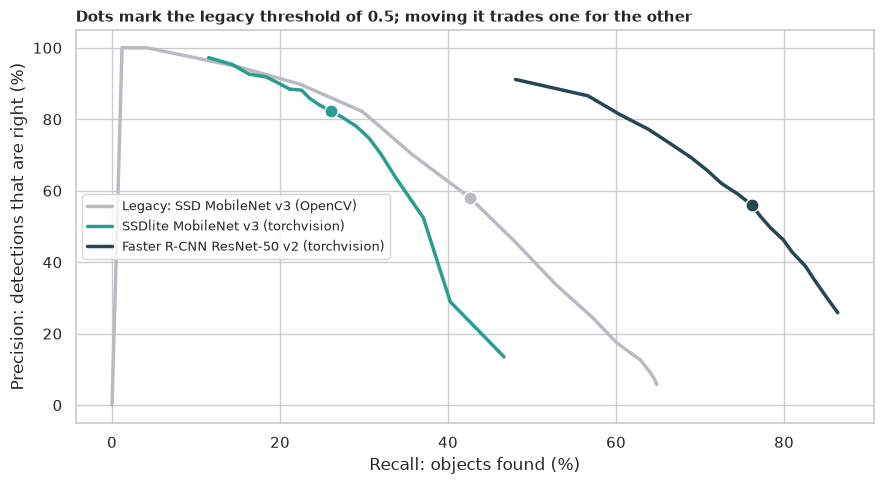

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in zip(detections, colors, strict=True):
    sub = sweep[(sweep["model"] == name) & (sweep["part"] == "hold")].sort_values("threshold")
    ax.plot(sub["recall"] * 100, sub["precision"] * 100, color=color, lw=2.5, label=name)
    half = sub[sub["threshold"] == LEGACY_THRESHOLD].iloc[0]
    ax.scatter(
        half["recall"] * 100,
        half["precision"] * 100,
        s=90,
        color=color,
        zorder=3,
        edgecolor="white",
    )
ax.set_xlabel("Recall: objects found (%)")
ax.set_ylabel("Precision: detections that are right (%)")
ax.set_title(
    "Dots mark the legacy threshold of 0.5; moving it trades one for the other",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_threshold_tradeoff.png", dpi=150)
plt.show()

**How to read this:**

- **For the legacy model 0.5 happens to be the best threshold:** the F1-maximising threshold on the tuning half is **0.50**; on the holdout half precision is **0.580**, recall **0.426** and F1 **0.491**. Fewer than half of the objects are found, and nearly half of the detections are wrong (precision 58%).
- **For other models 0.5 is not the best:** SSDlite is best at **0.25** (F1 **0.441** against **0.396** at 0.5: recall up from 0.261 to 0.337), and Faster R-CNN at **0.75** (F1 **0.697** against **0.646**: precision up from 0.561 to 0.732 at a cost in recall from 0.761 to 0.664).
- **The lesson:** a score of 0.5 means something different in each model; the threshold must be chosen for each detector and for the cost of a miss against a false alarm. The figure shows the whole precision-recall curve, with a dot at 0.5.

## 9. H4: crowded scenes and difficult categories

*What:* for the legacy detector at its threshold of 0.5, the share of the objects found in each image, against the number of objects in the image (Spearman correlation, and a Kruskal-Wallis test over four crowd levels). We also list the best and worst categories by AP. *Why:* the demo has two objects on a desk; the world has crowds.

In [8]:
legacy_name = list(detections)[0]
per_image = []
for i in image_ids:
    truth = coco.loadAnns(coco.getAnnIds(imgIds=[i], iscrowd=False))
    if not truth:
        continue
    tp, _, fn = match_counts(detections[legacy_name], [i], LEGACY_THRESHOLD)
    per_image.append({"image": i, "objects": len(truth), "recall": tp / (tp + fn)})
per_image = pd.DataFrame(per_image)
rho = stats.spearmanr(per_image["objects"], per_image["recall"])
per_image["crowd"] = pd.cut(
    per_image["objects"], [0, 2, 5, 10, 100], labels=["1-2 objects", "3-5", "6-10", "over 10"]
)
print("Legacy model at threshold 0.5, share of objects found per image:")
print(
    per_image.groupby("crowd", observed=True)["recall"].agg(["count", "mean"]).round(3).to_string()
)
print(
    f"Spearman correlation between objects per image and share found: "
    f"{rho.statistic:+.2f}, p = {fmt_p(rho.pvalue)}"
)
groups = [g["recall"].to_numpy() for _, g in per_image.groupby("crowd", observed=True)]
kw = stats.kruskal(*groups)
print(
    f"Kruskal-Wallis across the four crowd levels: H = {kw.statistic:.1f}, p = {fmt_p(kw.pvalue)}"
)

with contextlib.redirect_stdout(io.StringIO()):
    ev = COCOeval(
        coco,
        coco.loadRes([dict(d, image_id=i) for i in image_ids for d in detections[legacy_name][i]]),
        "bbox",
    )
    ev.params.imgIds = image_ids
    ev.evaluate()
    ev.accumulate()
precision = ev.eval["precision"][:, :, :, 0, 2]  # IoU, recall, category, area all, 100 dets
per_class = {}
for k, cat in enumerate(ev.params.catIds):
    p = precision[:, :, k]
    if (p > -1).any():
        per_class[names[cat]] = float(p[p > -1].mean()) * 100
per_class = pd.Series(per_class).sort_values()
print("\nLegacy model, AP by category (categories present in the sample):")
print("  best : " + ", ".join(f"{k} {v:.0f}" for k, v in per_class.tail(5)[::-1].items()))
print("  worst: " + ", ".join(f"{k} {v:.0f}" for k, v in per_class.head(5).items()))
print(f"  categories with AP below 5: {(per_class < 5).sum()} of {len(per_class)}")

Legacy model at threshold 0.5, share of objects found per image:
             count   mean
crowd                    
1-2 objects    155  0.819
3-5            126  0.590
6-10            89  0.457
over 10        126  0.324
Spearman correlation between objects per image and share found: -0.61, p = 1.3e-52
Kruskal-Wallis across the four crowd levels: H = 188.8, p = 1.1e-40



Legacy model, AP by category (categories present in the sample):
  best : cat 76, fire hydrant 64, train 63, zebra 61, parking meter 58
  worst: scissors 0, hair drier 0, knife 0, apple 2, handbag 3
  categories with AP below 5: 5 of 78


**How to read this:**

- **Crowds hurt a lot:** images with 1 to 2 objects have **81.9%** of their objects found, 3 to 5 objects **59.0%**, 6 to 10 objects **45.7%** and more than 10 objects only **32.4%**. The Spearman correlation between the number of objects and the share found is **-0.61** (p = 1e-52) and the Kruskal-Wallis p-value is 1e-40. **We reject H₀.** (Crowded images contain more small and overlapping objects, so this mixes several difficulties.)
- **Some categories are nearly invisible:** the best are cat (AP **76**), fire hydrant (**64**), train (**63**), zebra (**61**) and parking meter (**58**): large, distinctive things. The worst are scissors, hair drier and knife (**0**), apple (**2**) and handbag (**3**): small, thin or easily confused objects. **5 of 78** categories score below 5 AP.
- **A caution:** with 500 images a category with few objects (hair drier, scissors) has an AP that is close to noise.

## 10. H5: what does accuracy cost in time?

*What:* the median time to process one image, over 40 images, for each detector, with a bootstrap interval: the legacy model on the CPU (OpenCV), the two torchvision models on the GPU. *Why:* a detector for a live webcam has a budget of about 33 milliseconds per frame.

In [9]:
sample_ids = image_ids[:40]
timing_rows = []
for name, fn in models.items():
    fn(images[sample_ids[0]])  # warm-up
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    laps = []
    for i in sample_ids:
        start = time.perf_counter()
        fn(images[i])
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        laps.append((time.perf_counter() - start) * 1000)
    boots = [np.median(rng.choice(laps, len(laps))) for _ in range(1_000)]
    timing_rows.append(
        {
            "model": name,
            "ms per image": np.median(laps),
            "low": np.percentile(boots, 2.5),
            "high": np.percentile(boots, 97.5),
            "device": "CPU" if "OpenCV" in name else DEVICE,
        }
    )
timing = pd.DataFrame(timing_rows).set_index("model")
timing["mAP"] = table["mAP"]
print(timing.round(1).to_string())

                                         ms per image   low  high device   mAP
model                                                                         
Legacy: SSD MobileNet v3 (OpenCV)                28.9  28.4  29.5    CPU  27.6
SSDlite MobileNet v3 (torchvision)               42.4  41.6  43.0   cuda  22.1
Faster R-CNN ResNet-50 v2 (torchvision)          91.3  89.6  93.1   cuda  48.1


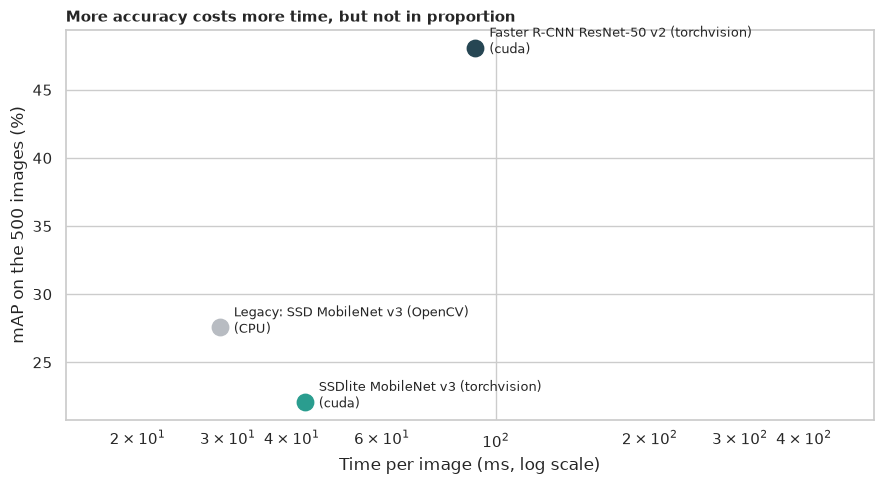

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for (name, row), color in zip(timing.iterrows(), colors, strict=True):
    ax.scatter(row["ms per image"], row["mAP"], s=140, color=color, zorder=3)
    ax.annotate(
        f"{name}\n({row['device']})",
        (row["ms per image"], row["mAP"]),
        textcoords="offset points",
        xytext=(10, -4),
        fontsize=9,
    )
ax.set_xscale("log")
ax.set_xlabel("Time per image (ms, log scale)")
ax.set_ylabel("mAP on the 500 images (%)")
ax.set_title(
    "More accuracy costs more time, but not in proportion",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.set_xlim(timing["ms per image"].min() / 2, timing["ms per image"].max() * 6)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_speed_vs_accuracy.png", dpi=150)
plt.show()

**How to read this:**

- **The legacy detector is the cheapest:** **28.9 ms** per image on the CPU (95% interval 28.4 to 29.5), inside the 33 ms budget of a 30-frames-per-second camera.
- **The big detector is about three times slower and almost twice as accurate:** Faster R-CNN takes **91.3 ms** per image on the GPU (89.6 to 93.1) for **48.1** mAP against **28.9 ms** for **27.6**.
- **SSDlite is slower than the legacy model and less accurate** (**42.4 ms**, **22.1** mAP), even on the GPU: for a tiny network the time goes into moving images to the GPU and into Python post-processing, not into the network.
- **The trade-off is not proportional:** three times the time buys 20 points of mAP (see the figure), but it also needs a GPU.

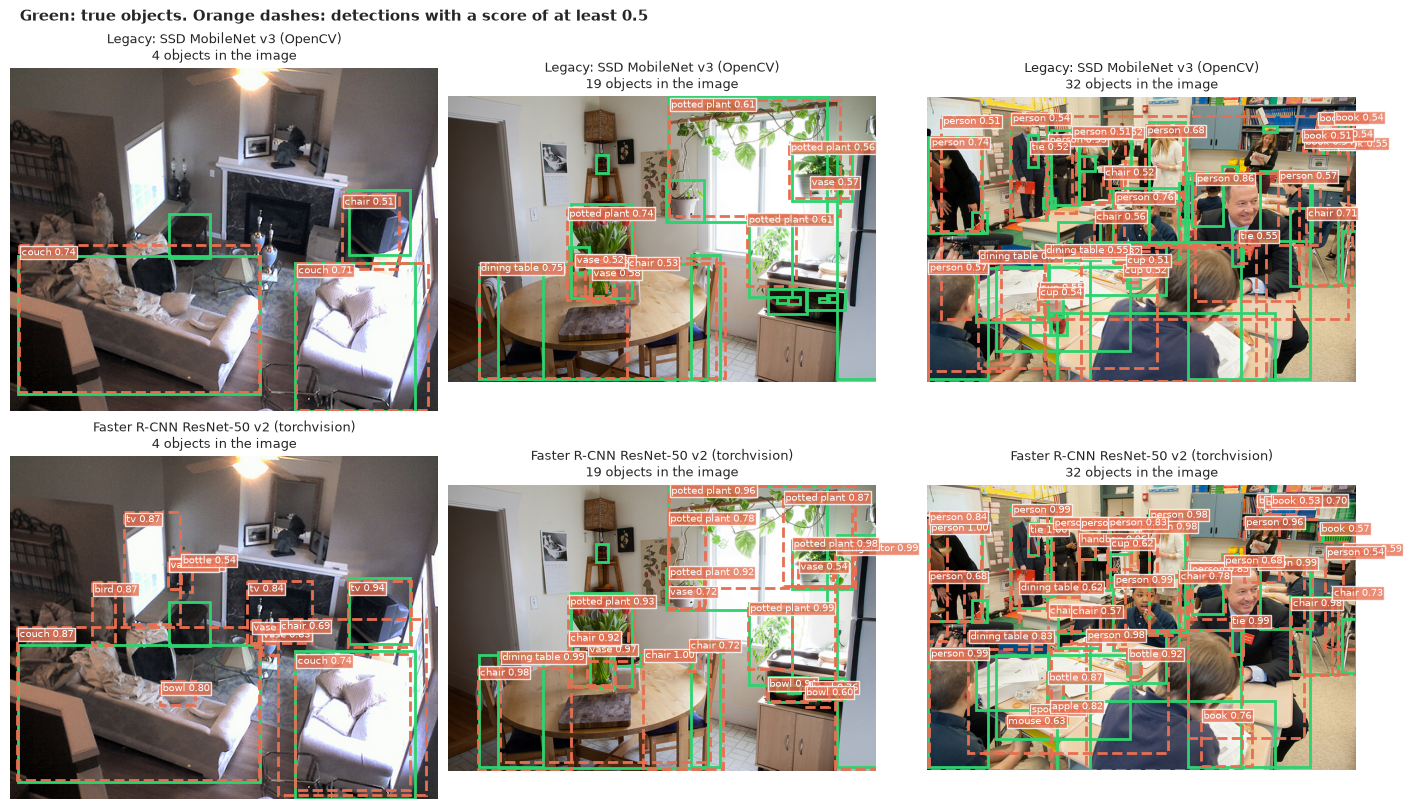

In [11]:
def draw(ax, image_id: int, dets: list[dict], threshold: float, title: str) -> None:
    """Shows an image with the true objects (green) and detections above ``threshold`` (orange)."""
    ax.imshow(cv2.cvtColor(images[image_id], cv2.COLOR_BGR2RGB))
    for t in coco.loadAnns(coco.getAnnIds(imgIds=[image_id], iscrowd=False)):
        x, y, w, h = t["bbox"]
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="#2dd36f", lw=2))
    for d in dets:
        if d["score"] >= threshold:
            x, y, w, h = d["bbox"]
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=ORANGE, lw=2, ls="--"))
            ax.text(
                x + 3,
                y + 12,
                f"{names.get(d['category_id'], '?')} {d['score']:.2f}",
                color="white",
                fontsize=7,
                bbox={"facecolor": ORANGE, "alpha": 0.8, "pad": 1},
            )
    ax.set_title(title, fontsize=9)
    ax.axis("off")


busy = per_image.sort_values("objects").iloc[[len(per_image) // 2, -40, -5]]["image"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
for col, image_id in enumerate(busy):
    for row, name in enumerate([legacy_name, list(detections)[2]]):
        draw(
            axes[row, col],
            image_id,
            detections[name][image_id],
            LEGACY_THRESHOLD,
            f"{name}\n{len(coco.getAnnIds(imgIds=[image_id], iscrowd=False))} objects in the image",
        )
fig.suptitle(
    "Green: true objects. Orange dashes: detections with a score of at least 0.5",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "01_examples.png", dpi=130)
plt.show()

## 11. 🎯 Takeaways

1. **The legacy detector scores 27.6 mAP** on 500 COCO images (AP 45.4 at IoU 0.5): good for a 29 ms model, far from solved.
2. **Size decides:** its AP is 59.4 on large objects and 5.3 on small ones, an 11-fold gap; 41% of objects in everyday photographs are small.
3. **Crowds hurt:** it finds 82% of the objects in images with 1 to 2 objects and 32% in images with more than 10.
4. **0.5 is a habit, not a law:** it is the best threshold for the legacy model (F1 0.491) but not for SSDlite (best 0.25) or Faster R-CNN (best 0.75).
5. **A bigger detector buys a lot:** Faster R-CNN reaches 48.1 mAP (+20.5) at about three times the time, and its advantage is mostly on small and medium objects.
6. **An "equivalent" network is not equivalent:** SSDlite from another recipe is 5.5 points below the legacy model.
7. **Measure with ground truth:** none of these numbers can be read from a webcam demo.

## 12. ⚠️ Limitations

- **500 images from one dataset.** COCO val2017 has everyday photographs with 80 categories; the numbers say nothing about a particular camera, room or object. The jackknife standard errors (about 1 to 2 mAP points) describe this sample.
- **The legacy mAP is higher than the published figure** for this model (see H1); we did not find the reason.
- **IoU 0.5 and the greedy matching in H3 are conventions,** and the F1 at one threshold ignores the category mix.
- **The three detectors are different in many ways** (recipe, input size, post-processing), so the comparison is between whole systems, not between single design choices.
- **Time is measured on one machine,** with the legacy model on the CPU and the others on the GPU, including Python pre- and post-processing; a different machine would change the ranking of the two small models.
- **Rare categories have a handful of examples** in 500 images, so their AP is noisy.
- **The crowd effect is confounded** with object size and overlap.
- **No fairness or privacy review:** COCO contains photographs of people, and person detection is only one of the 80 categories.